# 1. Importing libraries and dataset and dictionary

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()

In [2]:
# Importing Dataset
df = pd.read_csv("Salary_Data_Based_country_and_race.csv", index_col="Unnamed: 0")
# Renaming columns
df.columns = df.columns.str.replace(" ","_").str.lower()
# Printing first 5 rows
df.head()

,age,gender,education_level,job_title,years_of_experience,salary,country,race
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0,UK,White
1,28.0,Female,Master's,Data Analyst,3.0,65000.0,USA,Hispanic
2,45.0,Male,PhD,Senior Manager,15.0,150000.0,Canada,White
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0,USA,Hispanic
4,52.0,Male,Master's,Director,20.0,200000.0,USA,Asian


In [3]:
# Inspecting Dataset
print(f"The dataframe contains {df.isnull().sum().sum()} null values.")
print("=============== Total number of null values in each feature  ===============")
df_null = df.isnull().sum()
df_null = df_null[df_null>0]
df_null


The dataframe contains 17 null values.
=============== Total number of null values in each feature  ===============


age                    2
gender                 2
education_level        3
job_title              2
years_of_experience    3
salary                 5
dtype: int64

In [4]:
# Dropping null values
df = df.dropna()

# Reseting index
df.reset_index(drop =True, inplace=True)

In [5]:
# Dataframe shape
print(f"The dataframe contains {df.shape[0]} rows / recods, and {df.shape[1]} features / variables.")

The dataframe contains 6698 rows / recods, and 8 features / variables.


In [6]:
# Checking data types
df.dtypes

age                    float64
gender                     str
education_level            str
job_title                  str
years_of_experience    float64
salary                 float64
country                    str
race                       str
dtype: object

# Data Inspection and Cleaning

In [7]:
np.unique(df["education_level"])

array(["Bachelor's", "Bachelor's Degree", 'High School', "Master's",
       "Master's Degree", 'PhD', 'phD'], dtype=object)

In [8]:
df["education_level"] = np.where(df["education_level"]=="Master's","Master's Degree",
         np.where(df["education_level"] == "Bachelor's","Bachelor's Degree",
         np.where(df["education_level"] == "phD","PhD",df["education_level"])))

In [9]:
np.unique(df["race"])

array(['African American', 'Asian', 'Australian', 'Black', 'Chinese',
       'Hispanic', 'Korean', 'Mixed', 'Welsh', 'White'], dtype=object)

In [10]:
np.unique(df["country"])

array(['Australia', 'Canada', 'China', 'UK', 'USA'], dtype=object)

In [11]:
np.unique(df["gender"])

array(['Female', 'Male', 'Other'], dtype=object)

**Note:** Now that we have checked the features within the dataset and replace the values that contained typo and dropped the null values, I will proceed by plotting some charts to get some insights from our dataset.

----

In [12]:
df.to_csv("data_cleaned.csv")

----

# EDA visualizations

## Age feature

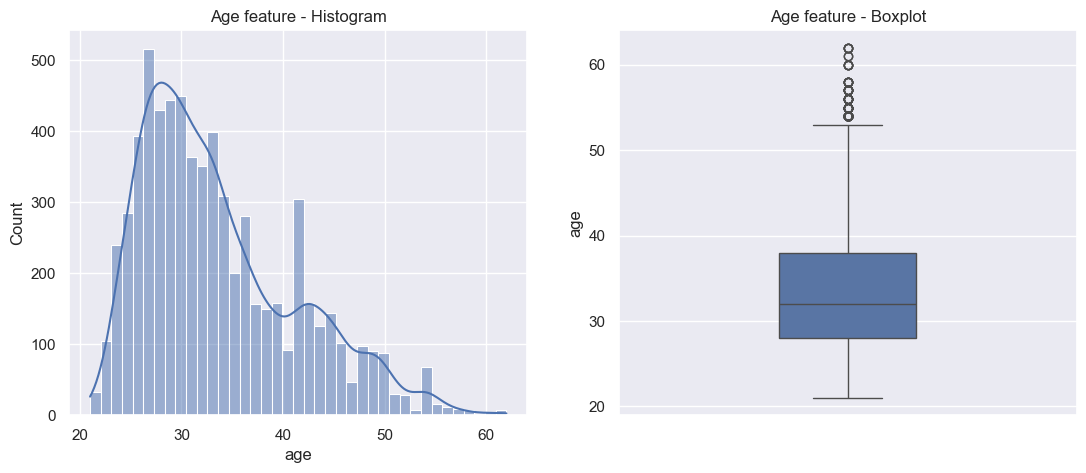

,count,mean,std,min,25%,50%,75%,max
age,6698.0,33.623022,7.615784,21.0,28.0,32.0,38.0,62.0


In [13]:
plt.figure(figsize=(13,5))
plt.subplot(1,2,1)
sns.histplot(df["age"], kde=True)
plt.title("Age feature - Histogram")
plt.subplot(1,2,2)
sns.boxplot(y=df["age"], width=0.3)
plt.title("Age feature - Boxplot")
plt.show()

df[["age"]].describe().T

**Findings:** I can confirm that the age feature is right (positive) skewed for which:

* The 50% of the employees are between 28 years and 38 years old (Interquartile Range)
* The youngest employee is 21 years old, whereas the elderly one is 62 years old
* The The standard deviation is 7.61 years old.

---

## Salary feature

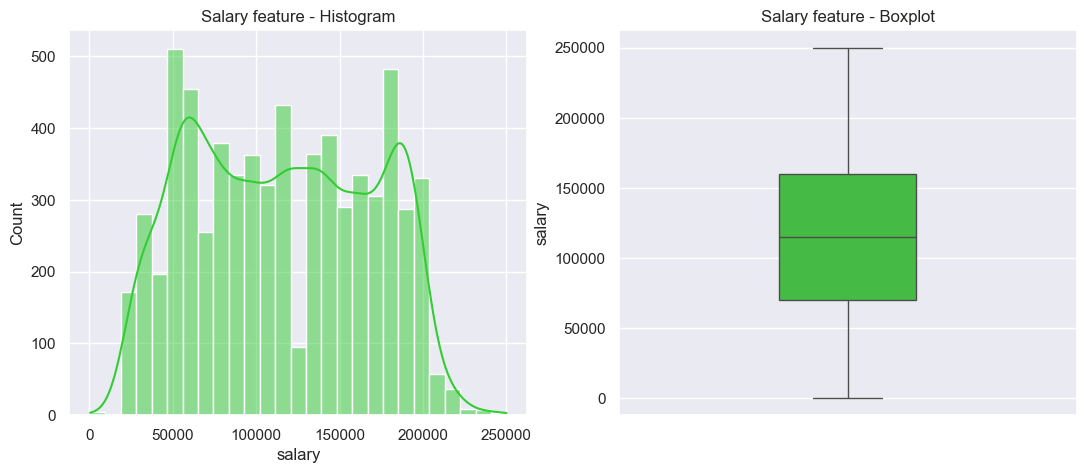

,count,mean,std,min,25%,50%,75%,max
salary,6698.0,115329.253061,52789.792507,350.0,70000.0,115000.0,160000.0,250000.0


In [14]:
plt.figure(figsize=(13,5))
plt.subplot(1,2,1)
sns.histplot(df["salary"], kde=True, color="limegreen")
plt.title("Salary feature - Histogram")
plt.subplot(1,2,2)
sns.boxplot(y=df["salary"], width=0.3, color="limegreen")
plt.title("Salary feature - Boxplot")
plt.show()

df[["salary"]].describe().T

**Findings:** By looking at the plots obtained, I can confirm that the salary feature is **binomial**, for which it means there are 2 peaks between the 50k and 60k, and another one between 180k and 200k.

* The 50% of the employees earns between 70K and 160K
* The employee who earns the least has a salary of 350 dollars whereas the employee that who earns the most has a salary of 250K.

---

## Salary / Education level boxplot

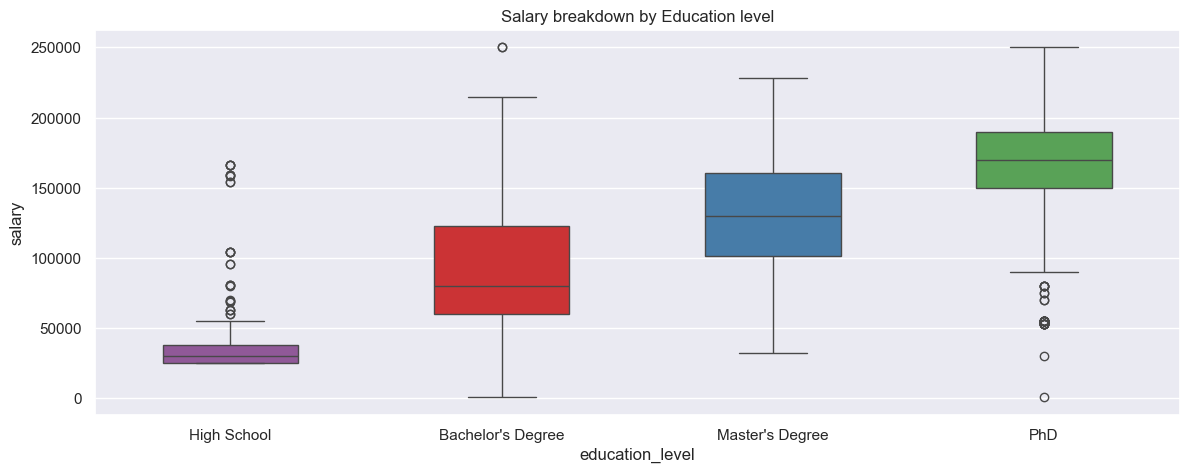

,count,mean,std,min,25%,50%,75%,max
education_level,,,,,,,,
Bachelor's Degree,3021.0,95082.91,44091.79,350.0,60000.0,80000.0,122485.0,250000.0
High School,448.0,36706.69,22549.13,25000.0,25000.0,30000.0,38000.0,166109.0
Master's Degree,1860.0,130112.06,40640.82,32000.0,101186.0,130000.0,160244.0,228000.0
PhD,1369.0,165651.46,34339.75,579.0,150000.0,170000.0,190000.0,250000.0


In [15]:
plt.figure(figsize=(14,5))
sns.boxplot(data=df, y="salary",
            x="education_level",
            width=0.5,
           order=["High School", "Bachelor's Degree", "Master's Degree", "PhD"],
            hue="education_level",
           palette="Set1")
plt.title("Salary breakdown by Education level")
plt.show()

df.groupby("education_level")["salary"].describe().round(2)

**Note:** I can confirm that there is an increase of salary in each education level by looking at the salary range for which the Interquartile Range is located.

* If we look up to the employees that only have a **High School degree**, I could say that the 50% of the them earn between 25K and 38K;
* The 50% of employees that hold a **Bachelor's Degree** earn between 60K and 122K;
* 50% of the employees that hold a **Master's Degree** earn between 100K and 150K;
* and finally, employees that hold a **PhD title** earn between 150K and 190K.

In each education level, I can confirm an improvement in the salary by looking at these values.

----

## Years of experience / Salary

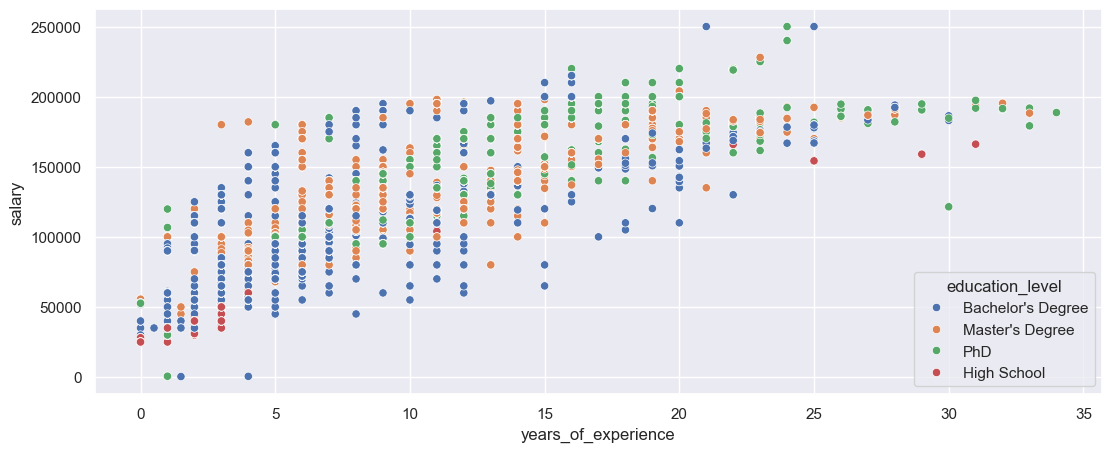

In [16]:
plt.figure(figsize=(13,5))
sns.scatterplot(data=df, x="years_of_experience", y="salary", hue="education_level")
plt.show()

**Note:** Here, I am looking at the relationship between the features *Years of experience* and *Salary*. The final aim about this is to understand the relationship between these features, and I could say that as more years of experience the employee has higher would be the salary.

----

# Encoding

In [17]:
gender = {"Male":0, "Female":1,"Other":2}
df["gender"] = df["gender"].map(gender)

In [18]:
education = {"Bachelor's Degree":1, 'High School':0, "Master's Degree":2, 'PhD':3}
df["education_level"] = df["education_level"].map(education)

In [19]:
df1 = df.groupby("job_title")["salary"].median().sort_values().reset_index()


dic_job = {}
for i in range(len(df1["job_title"])):
    dic_job[df1["job_title"].iloc[i]] = i

df["job_title"] = df["job_title"].map(dic_job)

In [20]:
countries = {"USA":0, "Canada":1, "UK":2, "Australia":3, "China": 4}
df["country"] = df["country"].map(countries)

In [21]:
df1 = df.groupby("race")["salary"].count().sort_values(ascending=False).reset_index()


dic_race = {}
for i in range(len(df1["race"])):
    dic_race[df1["race"].iloc[i]] = i

df["race"] = df["race"].map(dic_race)

---

### Check Point

In [22]:
df.to_csv("data_encoded.csv")

----

# Regular ML models

The dataset that I selected provides employees' information in regards of "Age", "Gender", **"Education Level"**, "Job title", "Years of experience", "Country", "Salary", and "Race". 

My scope in this project is to create 2 different type of machine learning models: **Classification** and **regression**. 

The final aim of classification models would be predict what education level the employee has based on the dependent features (Gender, age, job title, years of experience, salary and country). I will execute multiples models, explain the results obtained and select the one that best performs.

Whereas, the final end of **Regression models** would be predict the salary of the employees based on the dependent features.

In [50]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()

import warnings 
warnings.filterwarnings('ignore')

data = pd.read_csv("data_cleaned.csv", index_col="Unnamed: 0")
data.head(2)

,age,gender,education_level,job_title,years_of_experience,salary,country,race
0,32.0,Male,Bachelor's Degree,Software Engineer,5.0,90000.0,UK,White
1,28.0,Female,Master's Degree,Data Analyst,3.0,65000.0,USA,Hispanic


In [51]:
df = pd.read_csv("data_encoded.csv", index_col="Unnamed: 0")
df.head(2)

,age,gender,education_level,job_title,years_of_experience,salary,country,race
0,32.0,0,1,86,5.0,90000.0,2,0
1,28.0,1,2,130,3.0,65000.0,0,9


## Classification models - Supervised learning

In [52]:
from sklearn.decomposition import PCA 
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay, accuracy_score
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.linear_model import LogisticRegression
import sklearn.preprocessing as preproc
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

In [53]:
df = pd.read_csv("data_encoded.csv", index_col="Unnamed: 0")

# Reordering DataFrame 
df = df[['age', 'gender', 'education_level', 'job_title', 'years_of_experience',
       'salary','race','country']]

### Executing scaling

By following good practices learned in Data preparation, I will execute scaling only in numeric featuers and then apply PCA. 

#### Years of experience

<Axes: ylabel='years_of_experience'>

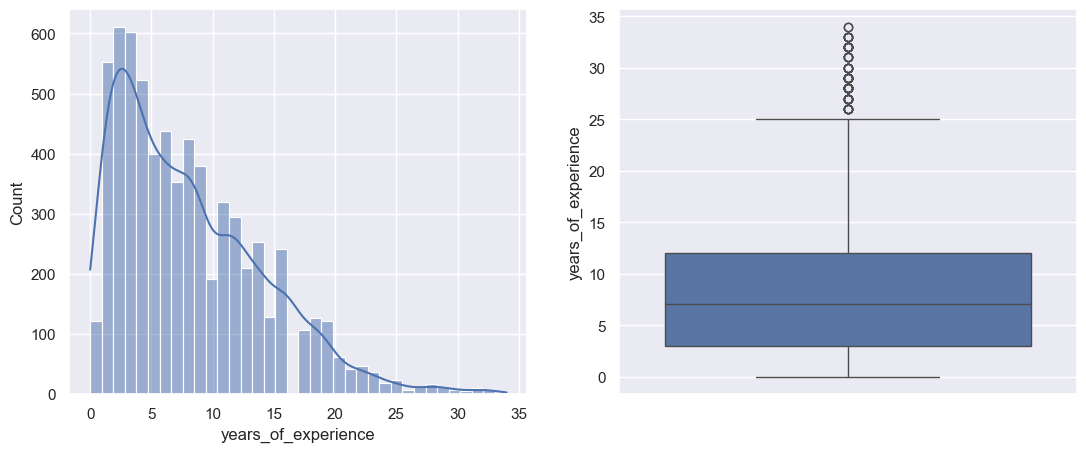

In [54]:
plt.figure(figsize=(13,5))
plt.subplot(1,2,1)
sns.histplot(df["years_of_experience"], kde=True)
plt.subplot(1,2,2)
sns.boxplot(df["years_of_experience"])

In [55]:
df["years_of_experience"] = preproc.minmax_scale(df["years_of_experience"])

#### salary

<Axes: ylabel='salary'>

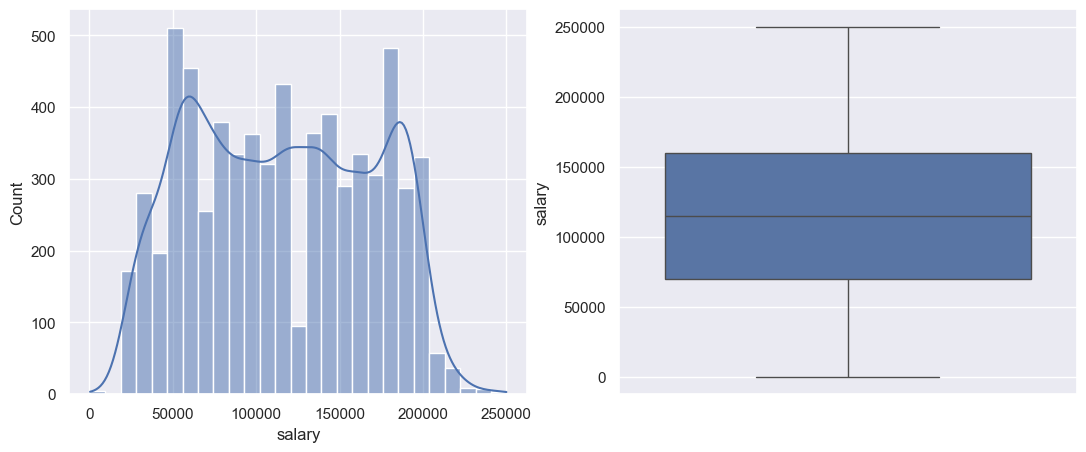

In [56]:
plt.figure(figsize=(13,5))
plt.subplot(1,2,1)
sns.histplot(df["salary"], kde=True)
plt.subplot(1,2,2)
sns.boxplot(df["salary"])

In [57]:
df["salary"] = preproc.minmax_scale(df[["salary"]])

#### Age

<Axes: ylabel='age'>

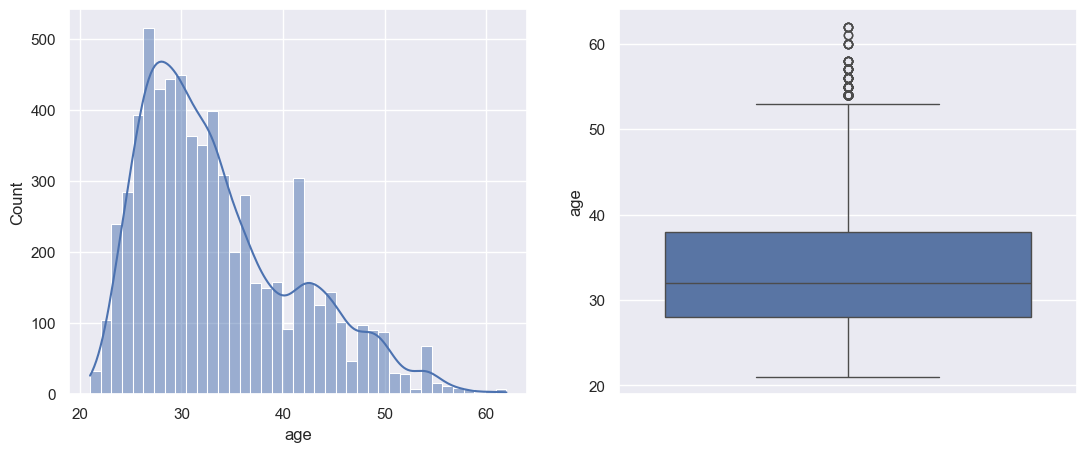

In [58]:
plt.figure(figsize=(13,5))
plt.subplot(1,2,1)
sns.histplot(df["age"], kde=True)
plt.subplot(1,2,2)
sns.boxplot(df["age"])

In [59]:
df["age"] = preproc.minmax_scale(df[["age"]])

----

### Defining Classifier for ML models

In [89]:
# Define classifiers for ML models
classifiers = {
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Support Vector Machine": SVC(kernel='linear', random_state=42)
}

### Train Test Split - Test size = 0.5

In [84]:
X = df.drop(columns=["education_level"])
y = df["education_level"]

In [96]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.05, random_state = 42, stratify = y)

X_train.shape , X_test.shape , y_train.shape , y_test.shape 

((6363, 7), (335, 7), (6363,), (335,))

In [97]:
# Train and evaluate ML model classifiers for Obesity dataset
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)

Model Performance Metrics on Test Set:
                    Model  Accuracy  Precision    Recall  F1 Score
0     k-Nearest Neighbors  0.752239   0.749533  0.752239  0.749835
1           Decision Tree  0.940299   0.940777  0.940299  0.940361
2           Random Forest  0.934328   0.934946  0.934328  0.934386
3     Logistic Regression  0.626866   0.629326  0.626866  0.627717
4  Support Vector Machine  0.629851   0.644262  0.629851  0.633716


In [ ]:
# Cross-validation for accuracy on the full dataset
cv_results = []
for name, classifier in classifiers.items():
    cv_scores = cross_val_score(classifier, X, y, cv=5, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores:")
print(cv_results_df)

### Train Test Split - Test size = 0.15

In [90]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = 42, stratify = y)

X_train.shape , X_test.shape , y_train.shape , y_test.shape 

((5693, 7), (1005, 7), (5693,), (1005,))

In [91]:
# Train and evaluate ML model classifiers for Obesity dataset
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)

Model Performance Metrics on Test Set:
                    Model  Accuracy  Precision    Recall  F1 Score
0     k-Nearest Neighbors  0.748259   0.744378  0.748259  0.744963
1           Decision Tree  0.923383   0.924478  0.923383  0.923684
2           Random Forest  0.931343   0.931542  0.931343  0.931417
3     Logistic Regression  0.660697   0.651650  0.660697  0.654290
4  Support Vector Machine  0.662687   0.666158  0.662687  0.663386


In [95]:
# Cross-validation for accuracy on the full dataset
cv_results = []
for name, classifier in classifiers.items():
    cv_scores = cross_val_score(classifier, X, y, cv=5, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores:")
print(cv_results_df)


Cross-Validation Accuracy Scores:
                    Model  Mean CV Accuracy
0     k-Nearest Neighbors          0.600625
1           Decision Tree          0.621367
2           Random Forest          0.659440
3     Logistic Regression          0.627638
4  Support Vector Machine          0.617187


-----

## Regression models

In [194]:
df = df[['age', 'gender', 'education_level', 'job_title', 'years_of_experience', 'country', 'race',"salary"]]

In [196]:
y = df["salary"] # Target column
X = df.drop(columns={"salary"}) # Independent columns

In [197]:
# Spliting the data
from sklearn.model_selection import train_test_split, cross_val_score, KFold
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

In [198]:
alpha_ridge = 10
alpha_lasso = 0.001


models = {
    "Linear": Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
    "Ridge": Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha = alpha_ridge))]),
    "Lasso": Pipeline([("scaler", StandardScaler()), ("model", Lasso(alpha = alpha_lasso, max_iter = 20000))]),
}

results = {}

print("\nTest Performance (MSE, R2, MAE Score)\n")

for name, pipe in models.items():
    pipe.fit(X_train, y_train) # Training the model
    preds = pipe.predict(X_test) # Predicting "y_test" by using X_test

    results[name] = {
        "MSE": mean_squared_error(y_test, preds), # calculating Mean_square_error
        "r2": r2_score(y_test, preds), # calculating R^2 score,
        "MAE": mean_absolute_error(y_test, preds),
        "coefficients": pipe.named_steps["model"].coef_, # Coeficient of the curve
        "intercept": pipe.named_steps["model"].intercept_ #Interception
}

    print(
        f"{name:6s} | "
        f"MSE = {results[name]['MSE']:.6f} | "
        f"R2^ Score = {results[name]['r2']:.6f} | "
        f"MAE = {results[name]['MAE']:.6f} | "
    )


lr, ri, la = (LinearRegression(), Ridge(alpha = alpha_ridge), Lasso(alpha = alpha_lasso,max_iter = 20000) )

lr.fit(X_train,y_train)
ri.fit(X_train,y_train)
la.fit(X_train,y_train)

r2_scores = []

k = 5
kf = KFold(n_splits=k, shuffle=True, random_state=42)


K_fold_models = [lr, ri, la]
for i in range(len(K_fold_models)):
    r2_scores.append(cross_val_score(K_fold_models[i], X, y,cv = kf, scoring = "r2"))


print("\n| K-fold results |\n")

print("Linear Regression | K-fold")
print("R2 for each fold:", r2_scores[0])
print("Average R2:", r2_scores[0].mean().round(5))
print("R2 std:", r2_scores[0].std().round(5))

print("\nRidge | K-fold")
print("R2 for each fold:", r2_scores[1])
print("Average R2:", r2_scores[1].mean().round(5))
print("R2 std:", r2_scores[1].std().round(5))


print("\nLasso | K-fold")
print("R2 for each fold:", r2_scores[2])
print("Average R2:", r2_scores[2].mean().round(5))
print("R2 std:", r2_scores[2].std().round(5))


Test Performance (MSE, R2, MAE Score)

Linear | MSE = 636209936.799388 | R2^ Score = 0.775891 | MAE = 18031.735910 | 
Ridge  | MSE = 636370179.126529 | R2^ Score = 0.775834 | MAE = 18024.028823 | 
Lasso  | MSE = 636209937.740361 | R2^ Score = 0.775891 | MAE = 18031.735539 | 

| K-fold results |

Linear Regression | K-fold
R2 for each fold: [0.78384406 0.75922104 0.7836623  0.78288685 0.77115625]
Average R2: 0.77615
R2 std: 0.00972

Ridge | K-fold
R2 for each fold: [0.7838425  0.75923629 0.78366059 0.78288021 0.77115667]
Average R2: 0.77616
R2 std: 0.00971

Lasso | K-fold
R2 for each fold: [0.78384406 0.75922105 0.7836623  0.78288685 0.77115625]
Average R2: 0.77615
R2 std: 0.00972
